# Supplementary Figure 3.5: Sequential structure in PD blocks 1–3

PD-task analog of `Figure03S04_sequentialAnalysis.ipynb`, restricted to **PD blocks
1-3** (raw 6-block numbering, low-SNR blocks -- same block/dataset convention as
`Figure03S04`/`Table_slopeAnalyses` and `Figure04S01_RRvsBoundPD`'s adaptation
panels).

## Why this isn't a straight port

`Figure03S04`'s Parts 1-3 work by comparing real bound estimates against a matched
*simulated* counterpart: same subject, a truly constant generative bound, run
through the same step-position bound-estimation pipeline (`get_bounds`) used on
real data. The point is to isolate how much trial-to-trial variability is just
measurement/estimation noise from that midpoint estimator, vs. genuine behavioral
change.

PD has no estimation step at all -- the recorded bound is exactly the value the
subject chose before the trial started -- so a fixed-bound simulated counterpart
would have essentially zero noise (SD=0, slope undefined, autocorrelation
undefined), making the original comparison degenerate for PD. This notebook
instead uses:

- **Part 0**: unchanged generic i.i.d. regression-to-mean demo (task-agnostic).
- **Parts 1 and 3** (slope, autocorrelation): a **within-subject trial-order
  shuffle null** -- the same real |bound| values, randomly reordered within each
  subject/block, destroying genuine temporal structure while preserving that
  subject's own value distribution (same style of permutation null as
  `pigeon.adaptation.compute_per_subject_curves_with_nulls`). The one-sample tests
  that don't need any comparator (real slope vs. -1, real ACF vs. 0) are unchanged
  from the original.
- **Part 2** (SD of |bound|): SD is order-invariant, so no shuffle can ever differ
  from the real value -- there's no meaningful null to build here regardless of the
  estimation-noise issue. Purely descriptive: histograms of per-subject SD of
  |bound|, no comparison/test.

**Adaptation-based trial exclusion** (applies to Parts 1-3, unchanged from
`Figure03S04`): for subjects with a *good* within-block adaptation τ fit in a given
block (`pigeon.adaptation.get_adaptation_tau_fits`, same eligibility/censoring
criteria as the τ insets in `Figure04S01_RRvsBoundPD` panels D-F), trials with
`trial_number < τ` are excluded from that subject's data in that block, on top of
the standard quality filters.

Per-block numeric summaries are printed for all three parts; a combined 3x3 figure
(rows = slope / SD histogram / lag-1 autocorrelation, columns = blocks) shows the
real-vs-shuffle-null-median comparisons (rows 1 and 3) and the SD histograms
(row 2). Saves to `Figure03_S06.pdf`.

## Imports

Imports standard scientific Python libraries and pigeon analysis functions. No
simulation import needed -- see the note above on why this notebook doesn't use a
matched-simulated comparison.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt

from pigeon.data import get_data_table, get_good_trial_array
from pigeon.adaptation import get_adaptation_tau_fits
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label, CONDITION_LABELS

plt.rcParams.update(FONT_RC)

RNG    = np.random.default_rng(12345)
N_PERM = 1000

## Part 0: Generic regression-to-mean demo

Direct port of the MATLAB `%% Regression to the mean` section (unchanged from
`Figure03S04_sequentialAnalysis`; task-agnostic). For a range of true bound means,
draw `N` i.i.d. bound *estimates* from `N(mean, std=0.1)` (truncated to `[0, 0.8]`),
then regress `diff(bounds) ~ bounds(1:end-1)` (the **previous** value). There is no
true bound change across draws -- the "trials" here are just repeated noisy
measurements of one fixed number -- yet the regression slope comes out near −1
across the whole range of means, and `-intercept/slope` recovers the true
generative mean (the fixed point of the artifact). PD itself has no measurement
noise of this kind, so this demo is background statistical context rather than a
live concern for PD's own data -- see Parts 1-3 below for what PD-specific
structure actually looks like.

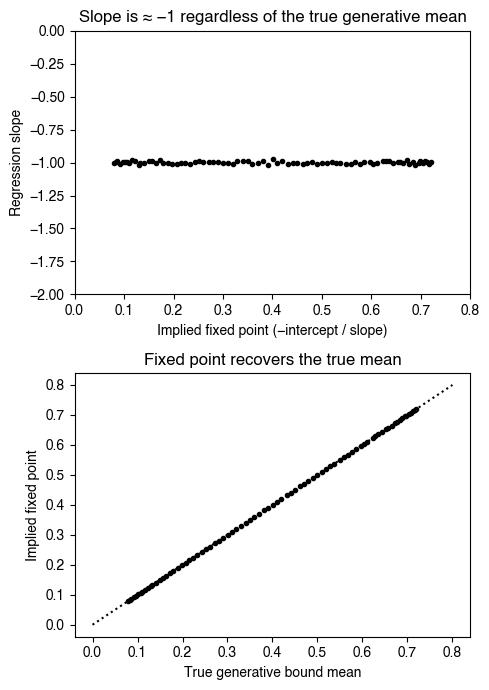

Slope across all generative means: median = -1.000, range = [-1.022, -0.972]


In [2]:
means      = np.arange(0, 0.8 + 0.01, 0.01)
STD        = 0.1
N          = 10_000

slopes     = np.full(len(means), np.nan)
intercepts = np.full(len(means), np.nan)
mean_bound = np.full(len(means), np.nan)

for mi, mean in enumerate(means):
    bounds = RNG.normal(mean, STD, N)
    bad = (bounds < 0) | (bounds > 0.8)
    while bad.any():
        bounds[bad] = RNG.normal(mean, STD, int(bad.sum()))
        bad = (bounds < 0) | (bounds > 0.8)

    delta_bounds = np.diff(bounds)
    slope, intercept, *_ = scipy.stats.linregress(bounds[:-1], delta_bounds)
    slopes[mi]     = slope
    intercepts[mi] = intercept
    mean_bound[mi] = bounds.mean()

fixed_point = -intercepts / slopes

fig, axs = plt.subplots(2, 1, figsize=(5, 7))

axs[0].plot(fixed_point, slopes, 'ko', ms=3)
axs[0].axis([0, 0.8, -2, 0])
axs[0].set_xlabel('Implied fixed point (−intercept / slope)')
axs[0].set_ylabel('Regression slope')
axs[0].set_title('Slope is ≈ −1 regardless of the true generative mean')

axs[1].plot(mean_bound, fixed_point, 'ko', ms=3)
axs[1].plot([0, 0.8], [0, 0.8], 'k:')
axs[1].set_xlabel('True generative bound mean')
axs[1].set_ylabel('Implied fixed point')
axs[1].set_title('Fixed point recovers the true mean')

plt.tight_layout()
plt.show()

print(f'Slope across all generative means: median = {np.nanmedian(slopes):.3f}, '
      f'range = [{np.nanmin(slopes):.3f}, {np.nanmax(slopes):.3f}]')

## Load PD data and compute per-subject |bound| sequences

Loads real PD trials (raw 6-block numbering, `combine_snr=False`), restricted to
blocks 1-3 (low-SNR blocks, same convention as `Figure03S04`/`Figure04S01_RRvsBoundPD`).

In [3]:
BLOCKS = [1, 2, 3]  # raw 6-block numbering, low-SNR blocks

data_table_pd = get_data_table(task_type='PD', combine_snr=False)

## Adaptation-based trial exclusion (applies to Parts 1-3)

Fits within-block adaptation τ per subject per block using
`pigeon.adaptation.get_adaptation_tau_fits` -- the same pipeline, eligibility
criteria, and 40-trial fit window as the τ insets in `Figure04S01_RRvsBoundPD`
panels D-F, run here on the PD block 1-3 data loaded above. `good_tau` holds the
fitted τ only for "good" fits (eligible, converged before the 40-trial window,
i.e. not censored); NaN elsewhere. `tau_exclusion_mask` returns a boolean
keep-mask for a data table: trials with `trial_number < ceil(τ)` are dropped for
subjects with a good fit in that block; all other subjects/trials are kept
unchanged.

In [4]:
tau_fits = get_adaptation_tau_fits(data_table_pd, blocks=BLOCKS, max_trial=40)
good_tau = tau_fits['good_tau']  # subject x block, NaN unless a good (uncensored) fit

n_good = good_tau.notna().sum()
n_total = np.sum(np.any(np.isfinite(tau_fits['real_curves']), axis=1), axis=0)
print('Subjects with a good tau fit, by block:')
for bi, b in enumerate(BLOCKS):
    print(f'  Block {b}: {int(n_good[b])}/{int(n_total[bi])}')


def tau_exclusion_mask(df, block):
    """Keep-mask dropping trials with trial_number < ceil(tau) for subjects
    with a good tau fit in `block`; True (no exclusion) for everyone else."""
    keep = pd.Series(True, index=df.index)
    for subj, tau in good_tau[block].dropna().items():
        drop = (df['subject_index'] == subj) & (df['trial_number'] < np.ceil(tau))
        keep &= ~drop
    return keep

Subjects with a good tau fit, by block:
  Block 1: 10/17
  Block 2: 11/19
  Block 3: 14/28


In [5]:
def per_subject_bounds(df, lg):
    # Return {subject_index: sorted-by-trial |bound| array} for good trials.
    out = {}
    for subj in np.sort(df.loc[lg, 'subject_index'].dropna().unique()):
        sub = df[lg & (df['subject_index'] == subj)].sort_values('trial_number')
        ab = np.abs(sub['bound'].to_numpy(dtype=float))
        ab = ab[np.isfinite(ab)]
        if len(ab) >= 4:
            out[subj] = ab
    return out


def delta_bound_slope(ab):
    # Regress against the PREVIOUS trial's |bound| (not current) so slope = -1
    # corresponds to classical regression to the mean (matches Part 0 and
    # Figure03S04's convention).
    prev, delta = ab[:-1], np.diff(ab)
    if len(prev) < 3 or np.ptp(prev) == 0:
        return np.nan
    slope, *_ = scipy.stats.linregress(prev, delta)
    return slope


MAX_LAG = 5
MIN_N   = MAX_LAG + 15

def subject_acf(ab, max_lag=MAX_LAG, min_n=MIN_N):
    if len(ab) < min_n:
        return np.full(max_lag, np.nan)
    out = np.full(max_lag, np.nan)
    for k in range(1, max_lag + 1):
        x, y = ab[:-k], ab[k:]
        if len(x) < 5 or np.ptp(x) == 0 or np.ptp(y) == 0:
            continue
        r, _ = scipy.stats.pearsonr(x, y)
        out[k - 1] = r
    return out


def med_iqr(x):
    q25, med, q75 = np.percentile(x, [25, 50, 75])
    return f'{med:.3f} [{q25:.3f}, {q75:.3f}]'


def shuffle_null(ab, stat_fn, n_perm, rng):
    """Null distribution of stat_fn under random within-subject trial-order
    shuffles of ab (same values, order destroyed). Returns shape (n_perm,) for
    a scalar-valued stat_fn (e.g. delta_bound_slope), or (n_perm, k) for a
    vector-valued one (e.g. subject_acf)."""
    return np.array([stat_fn(rng.permutation(ab)) for _ in range(n_perm)])


def perm_pvalue(real_val, null_vals):
    """Two-sided permutation p-value: how extreme real_val is relative to the
    null distribution (fraction of null values at least as extreme, doubled
    for two-sidedness, capped at 1)."""
    null_vals = np.asarray(null_vals, dtype=float)
    null_vals = null_vals[np.isfinite(null_vals)]
    if len(null_vals) == 0 or not np.isfinite(real_val):
        return np.nan
    p_lo = np.mean(null_vals <= real_val)
    p_hi = np.mean(null_vals >= real_val)
    return min(1.0, 2 * min(p_lo, p_hi))

## Parts 1-3 computation: real |bound| sequences and shuffle nulls (PD blocks 1-3)

For each block: restrict to real PD data, apply the standard quality filters plus
the τ-based exclusion above, and compute each subject's |bound| sequence (sorted by
trial number). From that sequence:

- **Slope** (Part 1) and **autocorrelation at lags 1-5** (Part 3): the real
  statistic, plus a null distribution from `N_PERM=1000` within-subject
  trial-order shuffles of that same sequence, and a two-sided permutation
  p-value.
- **SD** (Part 2): just the real value -- no null (SD doesn't depend on order, so
  a shuffle null is always identical to the real value by construction).

In [6]:
results = {}

for block in BLOCKS:
    real_block = data_table_pd[data_table_pd['block_index'] == block].reset_index(drop=True)
    good_real = (get_good_trial_array(real_block) & real_block['bound'].notna()
                 & tau_exclusion_mask(real_block, block))
    bounds_real = per_subject_bounds(real_block, good_real)

    slopes_real, slopes_null, slopes_p = {}, {}, {}
    acf_real, acf_null, acf_p = {}, {}, {}
    sd_real = {}

    for s, ab in bounds_real.items():
        sd_real[s] = np.std(ab, ddof=1)

        sl = delta_bound_slope(ab)
        if np.isfinite(sl):
            null_sl = shuffle_null(ab, delta_bound_slope, N_PERM, RNG)
            slopes_real[s] = sl
            slopes_null[s] = np.nanmedian(null_sl)
            slopes_p[s]    = perm_pvalue(sl, null_sl)

        racf = subject_acf(ab)
        if np.any(np.isfinite(racf)):
            null_acf = shuffle_null(ab, subject_acf, N_PERM, RNG)  # (N_PERM, MAX_LAG)
            acf_real[s] = racf
            acf_null[s] = np.nanmedian(null_acf, axis=0)
            acf_p[s]    = np.array([perm_pvalue(racf[k], null_acf[:, k]) for k in range(MAX_LAG)])

    results[block] = dict(
        bounds_real = bounds_real,
        sd_real     = pd.Series(sd_real),
        slopes_real = pd.Series(slopes_real),
        slopes_null = pd.Series(slopes_null),
        slopes_p    = pd.Series(slopes_p),
        acf_real    = pd.DataFrame(acf_real, index=np.arange(1, MAX_LAG + 1)).T,
        acf_null    = pd.DataFrame(acf_null, index=np.arange(1, MAX_LAG + 1)).T,
        acf_p       = pd.DataFrame(acf_p,    index=np.arange(1, MAX_LAG + 1)).T,
    )

    print(f'PD block {block}: {int(good_real.sum())} good trials, '
          f'{len(bounds_real)} subjects with usable |bound| sequences '
          f'({len(slopes_real)} with a valid slope, {len(acf_real)} with valid ACF)')

PD block 1: 6487 good trials, 59 subjects with usable |bound| sequences (55 with a valid slope, 48 with valid ACF)


PD block 2: 3652 good trials, 55 subjects with usable |bound| sequences (52 with a valid slope, 48 with valid ACF)


PD block 3: 2207 good trials, 51 subjects with usable |bound| sequences (45 with a valid slope, 40 with valid ACF)


## Part 1: Δ|bound| ~ previous |bound| slope, real vs. shuffle-null

Same regression as `Figure03S04` Part 1 / `Table_slopeAnalyses` analysis 2 /
`Figure03_boundSummary` Panel D, computed per subject in each block, compared
against each subject's own within-subject shuffle-null distribution (paired
Wilcoxon signed-rank test on real vs. null-median across subjects; per-subject
significance from the permutation p-values).

In [7]:
print(f'{"block":>6} {"real slope":>22} {"null-median slope":>20} {"n sig (p<.05)":>15} {"real vs -1 p":>13}')
for block in BLOCKS:
    r = results[block]
    sr, sn, sp = r['slopes_real'], r['slopes_null'], r['slopes_p']
    _, p_paired  = scipy.stats.wilcoxon(sr, sn)
    _, p_real_m1 = scipy.stats.wilcoxon(sr + 1)
    n_sig = int(np.sum(sp < 0.05))
    print(f'{block:>6} {med_iqr(sr):>22} {med_iqr(sn):>20} {f"{n_sig}/{len(sp)}":>15} {p_real_m1:>13.3g}'
          f'  (paired real-vs-null: p={p_paired:.3g})')

 block             real slope    null-median slope   n sig (p<.05)  real vs -1 p
     1 -0.152 [-0.318, -0.062] -1.012 [-1.030, -1.006]           52/55      1.31e-10  (paired real-vs-null: p=1.63e-10)
     2 -0.125 [-0.234, -0.045] -1.019 [-1.039, -1.012]           47/52      4.69e-10  (paired real-vs-null: p=5.15e-10)
     3 -0.079 [-0.240, -0.038] -1.025 [-1.035, -1.018]           41/45      1.71e-13  (paired real-vs-null: p=1.71e-13)


## Part 2: SD of |bound| estimates (descriptive)

Per-subject SD of |bound| within each block. Unlike `Figure03S04`'s version, this
is purely descriptive for PD: SD doesn't depend on trial order, so a shuffle null
is always identical to the real value by construction, and PD has no
measurement-noise floor to compare against in the first place (the bound is
exactly what the subject chose, not an estimate). Shown as histograms, not a
real-vs-comparator scatter.

In [8]:
print(f'{"block":>6} {"SD of |bound|":>20} {"n subjects":>12}')
for block in BLOCKS:
    sd = results[block]['sd_real']
    print(f'{block:>6} {med_iqr(sd):>20} {len(sd):>12}')

 block        SD of |bound|   n subjects
     1 0.088 [0.046, 0.126]           59
     2 0.072 [0.032, 0.109]           55
     3 0.040 [0.013, 0.070]           51


## Part 3: Sequential structure beyond lag-1 mean reversion

Under a "choose independently each trial" null, |bound| choices on different
trials would be unrelated -- the autocorrelation of the raw |bound| series should
be ≈ 0 at every lag. Real PD bounds may show additional structure (e.g. slow
drift, momentum, an error-triggered rise that decays back down -- the kind of
pattern seen in `Figure04S01_RRvsBoundPD` panel F) that a pure independent-choice
account would not predict. Autocorrelation is computed per subject at lags 1-5 and
compared against each subject's own within-subject shuffle-null distribution, lag
by lag.

In [9]:
for block in BLOCKS:
    r = results[block]
    print(f'--- PD block {block} ---')
    print(f'{"lag":>4} {"real median":>12} {"null median":>12} {"n sig (p<.05)":>14} {"real vs 0 p":>12}')
    for k in range(1, MAX_LAG + 1):
        real_k = r['acf_real'][k].dropna()
        null_k = r['acf_null'][k].loc[real_k.index]
        p_k    = r['acf_p'][k].loc[real_k.index]
        _, p_r0 = scipy.stats.wilcoxon(real_k)
        n_sig = int(np.sum(p_k < 0.05))
        print(f'{k:>4} {real_k.median():>12.3f} {null_k.median():>12.3f} {f"{n_sig}/{len(real_k)}":>14} {p_r0:>12.3g}')

--- PD block 1 ---
 lag  real median  null median  n sig (p<.05)  real vs 0 p
   1        0.879       -0.010          48/48     7.11e-15
   2        0.805       -0.010          47/48     7.11e-15
   3        0.697       -0.011          44/48     7.11e-15
   4        0.604       -0.010          37/48     3.55e-14
   5        0.560       -0.011          36/48     9.73e-13
--- PD block 2 ---
 lag  real median  null median  n sig (p<.05)  real vs 0 p
   1        0.902       -0.018          46/48     7.11e-15
   2        0.804       -0.018          46/48     1.42e-14
   3        0.699       -0.019          41/48     3.55e-14
   4        0.606       -0.018          36/48     3.18e-12
   5        0.476       -0.018          34/48     7.07e-11
--- PD block 3 ---
 lag  real median  null median  n sig (p<.05)  real vs 0 p
   1        0.894       -0.025          39/40     3.64e-12
   2        0.805       -0.024          38/40     1.82e-12
   3        0.714       -0.023          33/40     9.09e-12

## Combined figure: real vs. shuffle-null, all three parts x blocks 1-3

Rows: `Δ|bound| ~ previous |bound|` slope (real vs. shuffle-null median, per
subject), SD of |bound| (histogram, descriptive only), lag-1 autocorrelation (real
vs. shuffle-null median, per subject). Columns: PD blocks 1-3. In rows 1 and 3, the
dotted line is the identity `y = x`; points near it indicate the real data are
consistent with the shuffle null (no genuine order-dependent structure);
systematic offsets indicate real sequential structure beyond what the same values
in random order would show.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


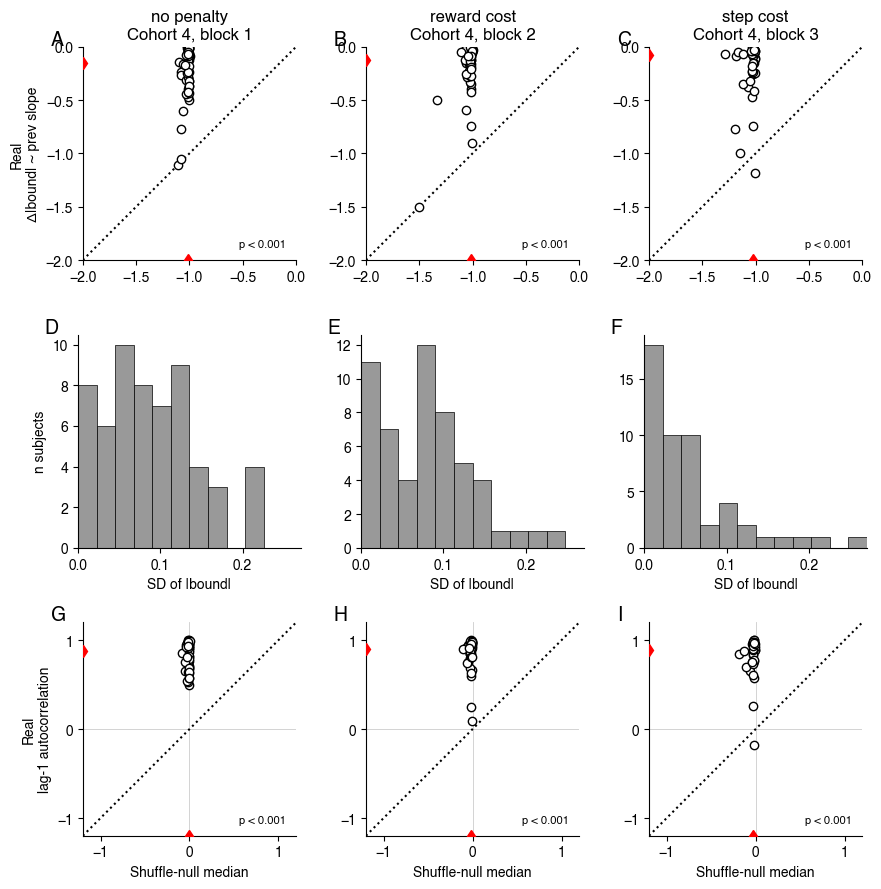

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S06.pdf (+ .png)


In [ ]:
def annotate_p(ax, p):
    txt = f'p = {p:.3g}' if p >= 0.001 else 'p < 0.001'
    ax.text(0.95, 0.05, txt, transform=ax.transAxes, ha='right', va='bottom', fontsize=8)


def add_median_markers(ax, xvals, yvals, edge):
    # Red diamond margin markers for the group medians of x and y, matching the
    # convention used elsewhere in this figure set (Figure02 panel 3, Figure03
    # panel E, Figure03S04's own combined figure).
    ax.plot(edge, np.nanmedian(yvals), 'rd', markerfacecolor='r', zorder=5)
    ax.plot(np.nanmedian(xvals), edge, 'rd', markerfacecolor='r', zorder=5)


def square_axes(ax, lo, hi):
    ax.axis([lo, hi, lo, hi])
    ax.set_box_aspect(1)
    ticks = ax.get_xticks()
    ticks = ticks[(ticks >= lo) & (ticks <= hi)]
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)


SUBJ_MS = 6

hi_sd = max(results[b]['sd_real'].max() for b in BLOCKS) * 1.05
m_row = max(
    0.05,
    max(
        pd.concat([results[b]['acf_real'][1], results[b]['acf_null'][1]]).dropna().abs().max()
        for b in BLOCKS
    ) * 1.2,
)

fig, axs = plt.subplots(3, len(BLOCKS), figsize=(3 * len(BLOCKS), 9))

for j, block in enumerate(BLOCKS):
    r = results[block]

    # Row 1: slope, real vs. shuffle-null median
    ax = axs[0, j]
    sr, sn = r['slopes_real'], r['slopes_null']
    lo, hi = -2, 0
    ax.plot([lo, hi], [lo, hi], 'k:')
    ax.plot(sn, sr, 'ko', mfc='w', ms=SUBJ_MS)
    add_median_markers(ax, sn, sr, lo)
    square_axes(ax, lo, hi)
    ax.set_title(f'{CONDITION_LABELS[block]}\nCohort 4, block {block}')
    if j == 0:
        ax.set_ylabel('Real\nΔ|bound| ~ prev slope')
    _, p_slope = scipy.stats.wilcoxon(sr, sn)
    annotate_p(ax, p_slope)
    add_panel_label(ax, chr(65 + 0 * len(BLOCKS) + j))

    # Row 2: SD histogram (descriptive, no comparator)
    ax = axs[1, j]
    sd = r['sd_real']
    ax.hist(sd, bins=12, range=(0, hi_sd), color='0.6', edgecolor='k', linewidth=0.5)
    ax.set_xlim(0, hi_sd)
    ax.set_xlabel('SD of |bound|')
    if j == 0:
        ax.set_ylabel('n subjects')
    add_panel_label(ax, chr(65 + 1 * len(BLOCKS) + j))

    # Row 3: lag-1 autocorrelation, real vs. shuffle-null median
    ax = axs[2, j]
    r1, n1 = r['acf_real'][1], r['acf_null'][1]
    ok = r1.notna() & n1.notna()
    r1_ok, n1_ok = r1[ok], n1[ok]
    ax.axhline(0, color='0.8', lw=0.6, zorder=0)
    ax.axvline(0, color='0.8', lw=0.6, zorder=0)
    ax.plot([-m_row, m_row], [-m_row, m_row], 'k:')
    ax.plot(n1_ok, r1_ok, 'ko', mfc='w', ms=SUBJ_MS)
    add_median_markers(ax, n1_ok, r1_ok, -m_row)
    square_axes(ax, -m_row, m_row)
    if j == 0:
        ax.set_ylabel('Real\nlag-1 autocorrelation')
    ax.set_xlabel('Shuffle-null median')
    _, p_acf1 = scipy.stats.wilcoxon(r1_ok, n1_ok)
    annotate_p(ax, p_acf1)
    add_panel_label(ax, chr(65 + 2 * len(BLOCKS) + j))

for ax in axs.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
out = FIGURES_DIR / 'Figure03_S05.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')